# Курсовой проект по дисциплине «Технологии обработки больших данных»

**Тема:** «Исследование предпочтений в музыке на основе потоковых и текстовых данных»  
**Этап:** 2.4. Применение алгоритмов анализа данных и машинного обучения

На предыдущем этапе был подготовлен объединенный набор данных: очищенные недельные данные Spotify, показатели Last.fm, метаданные MusicBrainz и текстовые признаки The Guardian.

На этапе 2.4 проверяется аналитическая гипотеза:

> **популярность музыкального контента связана с его потоковыми, содержательными и текстовыми характеристиками, а анализ этих признаков позволяет различать более и менее популярные композиции.**

Для проверки используются:
- корреляционный анализ;
- бинарная классификация популярности;
- логистическая регрессия;
- Random Forest;
- кластеризация K-Means;
- отдельная проверка вклада текстовых признаков The Guardian, если они доступны после выполнения этапа 2.3.


## 1. Критерий проверки гипотезы

Чтобы вывод не был субъективным, заранее задаются проверяемые критерии.

Основная часть гипотезы считается поддержанной данными, если:
1. не менее трех признаков имеют заметную связь с `log(streams)` по коэффициенту Спирмена: `|ρ| ≥ 0.10`;
2. хотя бы одна ML-модель показывает `ROC-AUC ≥ 0.65` на тестовой выборке и превосходит Dummy baseline;
3. результаты моделей получены без использования признаков, которые напрямую описывают текущую позицию трека в чарте.

Для текстовой части отдельно сравнивается качество модели **без** и **с** признаками The Guardian на одной и той же подвыборке. Если текстовые признаки повышают ROC-AUC хотя бы на 0.02, это рассматривается как дополнительное подтверждение их полезности.

Порог 0.02 используется как практический критерий улучшения, а не как универсальная статистическая граница.


## 2. Подключение библиотек и загрузка данных

Сначала используется итоговый файл `data/processed/music_merged.csv`, который создается в 2.3. Если файл не найден, ноутбук автоматически загрузит и очистит только основной Spotify-набор. В этом резервном режиме основная ML-часть выполнится, но анализ текстовых признаков будет пропущен.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, silhouette_score
)
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

PROCESSED_CANDIDATES = [
    Path("data/processed/music_merged.csv"),
    Path("../data/processed/music_merged.csv"),
]

SPOTIFY_URL = (
    "https://raw.githubusercontent.com/younver/"
    "spotify-top-200-dataset/main/spotify-top-200-dataset.csv"
)

processed_path = next(
    (p for p in PROCESSED_CANDIDATES if p.exists()),
    None
)

if processed_path is not None:
    df = pd.read_csv(processed_path, low_memory=False)
    source_mode = "merged"
    print("Загружен объединенный набор:", processed_path)
else:
    print(
        "Файл 2.3 не найден. Загружается резервный Spotify-набор.\n"
        "Для проверки текстовой части запустите 2.3 в той же рабочей папке."
    )
    raw = pd.read_csv(SPOTIFY_URL, sep=";", low_memory=False)

    if "pivot" in raw.columns:
        pivot_num = pd.to_numeric(raw["pivot"], errors="coerce").fillna(0)
        raw = raw[pivot_num == 0].copy()

    raw["week"] = pd.to_datetime(raw["week"], errors="coerce")
    raw["release_date"] = pd.to_datetime(raw["release_date"], errors="coerce")
    raw = raw.dropna(subset=["track_name", "artist_name", "week", "streams"])

    if {"track_id", "week"}.issubset(raw.columns):
        raw = raw.drop_duplicates(["track_id", "week"], keep="first")

    df = raw.copy()
    source_mode = "spotify_only"

print("Режим:", source_mode)
print("Размер:", df.shape)
display(df.head())


Загружен объединенный набор: data/processed/music_merged.csv
Режим: merged
Размер: (44195, 61)


,track_id,track_name,track_popularity,track_number,album_id,album_name,album_img,album_type,album_label,album_track_number,album_popularity,artist_num,artist_names,artist_id,artist_name,artist_img,artist_followers,artist_popularity,artist_genres,rank,week,collab,explicit,release_date,danceability,energy,key,mode,time_signature,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration,pivot,streams,track_index,artist_key,track_key,lfm_mbid,lfm_duration,listeners,playcount,lfm_album,lfm_tags,mbid,mb_type,mb_name,country,gender,active_begin,active_end,alias_count,article_count,avg_article_words,total_artist_mentions,avg_text_length,avg_tag_count
0,5aAx2yezTd8zXrkmtKl66Z,Starboy,0,1,09fggMHib4YkOtwQNXEBII,Starboy,https://i.scdn.co/image/ab67616d0000b2730c8599...,album,Universal Music Group,1,0,2,"The Weeknd, Daft Punk",1Xyo4u8uXC1ZmMpatF05PJ,The Weeknd,https://i.scdn.co/image/ab6761610000e5ebb5f9e2...,51215861,94,"canadian contemporary r&b, canadian pop, pop",1,2017-01-06,True,True,2016-11-25,0.681,0.594,7,True,4,-7.028,0.2820,0.1650,0.000003,0.134,0.5350,186.054,230453,False,25734078,1,the weeknd,starboy,NaN,NaN,NaN,NaN,NaN,NaN,c8b03190-306c-4120-bb0b-6f2ebfc06ea9,Person,The Weeknd,CA,male,1990-02-16,NaN,7.0,5.0,1164.0,24.0,6243.0,6.6
1,7BKLCZ1jbUBVqRi2FVlTVw,Closer,84,1,0rSLgV8p5FzfnqlEk4GzxE,Closer,https://i.scdn.co/image/ab67616d0000b273495ce6...,single,Disruptor Records/Columbia,1,71,2,"The Chainsmokers, Halsey",69GGBxA162lTqCwzJG5jLp,The Chainsmokers,https://i.scdn.co/image/ab6761610000e5eb3c02f4...,19562506,81,"dance pop, edm, electropop, pop, pop dance, tr...",2,2017-01-06,True,False,2016-07-29,0.748,0.524,8,True,4,-5.599,0.0338,0.4140,0.000000,0.111,0.6610,95.010,244960,False,23519705,2,the chainsmokers,closer,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,5knuzwU65gJK7IF5yJsuaW,Rockabye (feat. Sean Paul & Anne-Marie),75,1,3meZFplbMmji648oWUNEfQ,Rockabye (feat. Sean Paul & Anne-Marie),https://i.scdn.co/image/ab67616d0000b2731431c3...,single,Atlantic Records UK,1,62,3,"Clean Bandit, Sean Paul, Anne-Marie",6MDME20pz9RveH9rEXvrOM,Clean Bandit,https://i.scdn.co/image/ab6761610000e5eb7a4870...,4943046,76,"dance pop, edm, pop, pop dance, post-teen pop,...",3,2017-01-06,True,False,2016-10-21,0.720,0.763,9,False,4,-4.068,0.0523,0.4060,0.000000,0.180,0.7420,101.965,251088,False,21216399,3,clean bandit,rockabye feat sean paul anne marie,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4pdPtRcBmOSQDlJ3Fk945m,Let Me Love You,2,13,55bbXORm6ZrVq52zfZnxBf,Encore,https://i.scdn.co/image/ab67616d0000b2735045de...,album,Universal Music Group,13,0,2,"DJ Snake, Justin Bieber",540vIaP2JwjQb9dm3aArA4,DJ Snake,https://i.scdn.co/image/ab6761610000e5ebf2855e...,8137850,78,"dance pop, edm, electronic trap, pop, pop danc...",4,2017-01-06,True,False,2016-08-05,0.476,0.718,8,True,4,-5.309,0.0576,0.0784,0.000010,0.122,0.1420,199.864,205946,False,19852704,4,dj snake,let me love you,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3NdDpSvN911VPGivFlV5d0,I Don’t Wanna Live Forever (Fifty Shades Darke...,0,1,5MxXY7DbFMUiHFTPUabgJJ,I Don’t Wanna Live Forever (Fifty Shades Darker),https://i.scdn.co/image/ab67616d0000b2732ae921...,single,Universal Music Group,1,0,2,"ZAYN, Taylor Swift",5ZsFI1h6hIdQRw2ti0hz81,ZAYN,https://i.scdn.co/image/ab6761610000e5eb9fbf71...,21433236,77,"dance pop, pop, post-teen pop, uk pop",5,2017-01-06,True,False,2016-12-09,0.735,0.451,0,True,4,-8.374,0.0585,0.0631,0.000013,0.325,0.0862,117.973,245200,False,18316326,5,zayn,i don t wanna live forever fifty shades darker...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Подготовка признаков для анализа

Целевой показатель — недельное число прослушиваний `streams`.

Для уменьшения влияния сильной асимметрии дополнительно используется `log_streams = log(1 + streams)`.

Для классификации создается бинарный признак `popular`:
- 1 — наблюдение относится к верхним 25% по числу стримов;
- 0 — остальные 75%.

Из ML-признаков специально исключаются `rank`, `track_popularity` и `album_popularity`, потому что они уже непосредственно отражают текущую популярность и сделали бы задачу искусственно простой.


In [2]:
# Приведение типов
df["streams"] = pd.to_numeric(df["streams"], errors="coerce")
df = df.dropna(subset=["streams"]).copy()

for col in ["week", "release_date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# Простые производные признаки
df["log_streams"] = np.log1p(df["streams"])

if "artist_followers" in df.columns:
    df["artist_followers"] = pd.to_numeric(
        df["artist_followers"], errors="coerce"
    )
    df["log_artist_followers"] = np.log1p(df["artist_followers"])

if {"week", "release_date"}.issubset(df.columns):
    df["release_age_days"] = (
        df["week"] - df["release_date"]
    ).dt.days.clip(lower=0)

for col in ["explicit", "collab"]:
    if col in df.columns:
        df[col] = (
            df[col].astype(str).str.lower()
            .map({"true": 1, "false": 0, "1": 1, "0": 0})
        )

popular_threshold = df["streams"].quantile(0.75)
df["popular"] = (df["streams"] >= popular_threshold).astype(int)

print(f"Порог верхнего квартиля streams: {popular_threshold:,.0f}")
print("Доли классов:")
display(df["popular"].value_counts(normalize=True).rename("share").to_frame())


Порог верхнего квартиля streams: 9,612,280
Доли классов:


,share
popular,
0,0.749994
1,0.250006


## 4. Описательный анализ популярности

Перед ML посмотрим на распределение `streams` и его изменение во времени. Это позволяет убедиться, что целевой показатель действительно сильно варьируется и его имеет смысл анализировать.


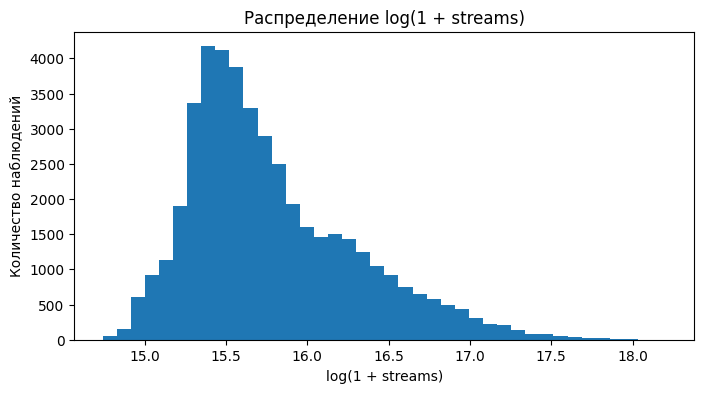

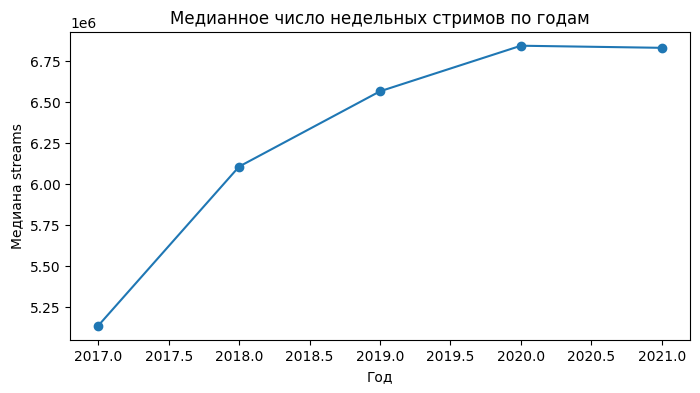

,year,streams
0,2017,5134097.0
1,2018,6103827.0
2,2019,6562676.5
3,2020,6840269.0
4,2021,6827455.0


In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["log_streams"], bins=40)
ax.set_title("Распределение log(1 + streams)")
ax.set_xlabel("log(1 + streams)")
ax.set_ylabel("Количество наблюдений")
plt.show()

if "week" in df.columns:
    yearly = (
        df.assign(year=df["week"].dt.year)
        .groupby("year", as_index=False)["streams"]
        .median()
    )

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(yearly["year"], yearly["streams"], marker="o")
    ax.set_title("Медианное число недельных стримов по годам")
    ax.set_xlabel("Год")
    ax.set_ylabel("Медиана streams")
    plt.show()

    display(yearly)


## 5. Корреляционный анализ

Для количественных признаков используется коэффициент Спирмена. Он выбран потому, что не требует нормального распределения и оценивает монотонную связь.

Корреляции рассчитываются с `log_streams`. Значения сортируются по модулю, чтобы увидеть факторы, наиболее заметно связанные с популярностью.


,feature,spearman_rho,abs_rho
0,release_age_days,-0.238497,0.238497
1,duration,-0.115641,0.115641
2,artist_popularity,0.103623,0.103623
3,playcount,0.098530,0.098530
4,log_artist_followers,0.082124,0.082124
5,total_artist_mentions,-0.072768,0.072768
6,listeners,0.071717,0.071717
7,danceability,0.059072,0.059072
8,avg_article_words,-0.036903,0.036903
9,valence,0.034980,0.034980


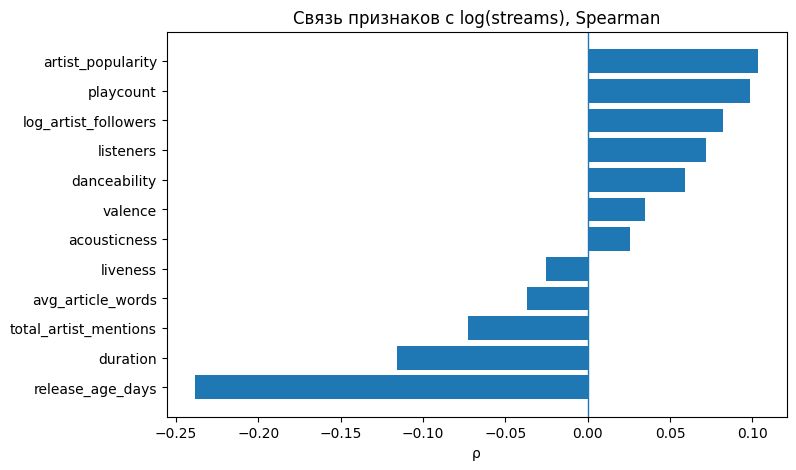

In [4]:
candidate_corr_features = [
    "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence",
    "tempo", "duration", "artist_popularity",
    "log_artist_followers", "release_age_days",
    "listeners", "playcount",
    "avg_article_words", "total_artist_mentions",
    "avg_text_length", "avg_tag_count"
]

corr_features = [
    c for c in candidate_corr_features
    if c in df.columns and pd.to_numeric(df[c], errors="coerce").notna().sum() > 20
]

corr_df = df[corr_features + ["log_streams"]].copy()
for col in corr_features:
    corr_df[col] = pd.to_numeric(corr_df[col], errors="coerce")

corr_series = (
    corr_df.corr(method="spearman")["log_streams"]
    .drop("log_streams")
    .dropna()
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

corr_table = pd.DataFrame({
    "feature": corr_series.index,
    "spearman_rho": corr_series.values,
    "abs_rho": corr_series.abs().values
})

display(corr_table)

top_corr = corr_table.head(12).sort_values("spearman_rho")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_corr["feature"], top_corr["spearman_rho"])
ax.axvline(0, linewidth=1)
ax.set_title("Связь признаков с log(streams), Spearman")
ax.set_xlabel("ρ")
plt.show()


### Интерпретация корреляций

Знак коэффициента показывает направление связи, а модуль — ее выраженность. Корреляция сама по себе не доказывает причинно-следственную связь, поэтому далее используются модели классификации.

Особенно важно, что `rank` не включен в таблицу: сильная связь позиции чарта со стримами была бы ожидаемой, но не помогла бы проверить содержательную гипотезу.


## 6. Формирование выборки для машинного обучения

Основная задача ML: по характеристикам композиции и исполнителя определить, относится ли недельное наблюдение к верхним 25% по `streams`.

Используемые признаки:
- аудиохарактеристики;
- длительность и возраст релиза;
- признаки explicit и collaboration;
- характеристики популярности исполнителя, существующие независимо от конкретной позиции трека в текущей неделе.

Чтобы одинаковая композиция не оказалась одновременно в обучении и тесте, применяется **GroupShuffleSplit по track_id**. Это уменьшает риск утечки данных между выборками.


In [5]:
model_features = [
    "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence",
    "tempo", "duration", "artist_popularity",
    "log_artist_followers", "release_age_days",
    "explicit", "collab"
]

model_features = [c for c in model_features if c in df.columns]

group_col = "track_id" if "track_id" in df.columns else "track_key"

model_df = df[model_features + ["popular", group_col]].copy()

for col in model_features:
    model_df[col] = pd.to_numeric(model_df[col], errors="coerce")

model_df = model_df.dropna(subset=model_features + ["popular", group_col])

X = model_df[model_features]
y = model_df["popular"]
groups = model_df[group_col]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Обучение:", X_train.shape)
print("Тест:", X_test.shape)
print("Доля popular в train:", round(y_train.mean(), 3))
print("Доля popular в test:", round(y_test.mean(), 3))
print("Пересечение track_id между train/test:",
      len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))


Обучение: (32797, 15)
Тест: (10814, 15)
Доля popular в train: 0.248
Доля popular в test: 0.266
Пересечение track_id между train/test: 0


## 7. Базовая модель Dummy

DummyClassifier не ищет закономерности в признаках и нужен как контрольная точка. ML-модель должна превосходить такой baseline, иначе ее использование не имеет практического смысла.


In [6]:
def evaluate_classifier(name, model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        score = model.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, score)
    else:
        auc = np.nan

    return {
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": auc
    }, model, pred

results = []

dummy = DummyClassifier(strategy="prior", random_state=42)
dummy_result, dummy_model, dummy_pred = evaluate_classifier(
    "Dummy baseline",
    dummy,
    X_train, y_train, X_test, y_test
)
results.append(dummy_result)

display(pd.DataFrame(results))


,model,accuracy,precision,recall,f1,roc_auc
0,Dummy baseline,0.733771,0.0,0.0,0.0,0.5


## 8. Логистическая регрессия

Логистическая регрессия — интерпретируемая линейная модель. Перед обучением признаки стандартизируются, чтобы коэффициенты были сопоставимы по масштабу.

Используется `class_weight="balanced"`, поскольку популярный класс составляет только около четверти наблюдений.


In [7]:
logistic = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

log_result, logistic_model, log_pred = evaluate_classifier(
    "Logistic Regression",
    logistic,
    X_train, y_train, X_test, y_test
)

results.append(log_result)
display(pd.DataFrame(results))


,model,accuracy,precision,recall,f1,roc_auc
0,Dummy baseline,0.733771,0.000000,0.000000,0.000000,0.500000
1,Logistic Regression,0.540133,0.305463,0.571032,0.398015,0.568748


## 9. Random Forest

Random Forest способен находить нелинейные зависимости и взаимодействия между признаками. В отличие от логистической регрессии, он не предполагает линейную форму связи.


,model,accuracy,precision,recall,f1,roc_auc
2,Random Forest,0.689,0.413,0.399,0.406,0.675
1,Logistic Regression,0.540,0.305,0.571,0.398,0.569
0,Dummy baseline,0.734,0.000,0.000,0.000,0.500


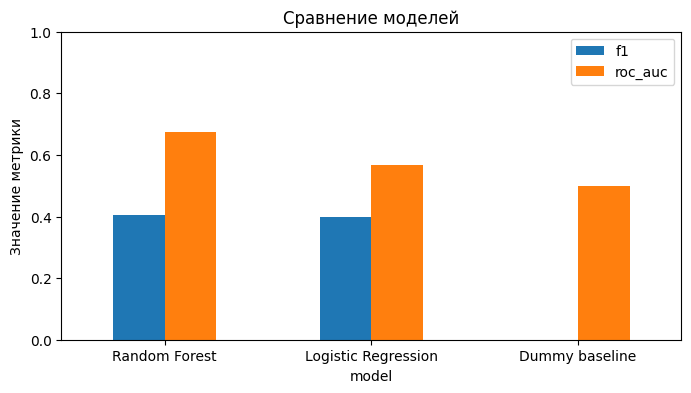

In [8]:
forest = RandomForestClassifier(
    n_estimators=250,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_result, forest_model, rf_pred = evaluate_classifier(
    "Random Forest",
    forest,
    X_train, y_train, X_test, y_test
)

results.append(rf_result)

results_df = pd.DataFrame(results).sort_values(
    "roc_auc", ascending=False
)

display(results_df.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
plot_df = results_df.set_index("model")[["f1", "roc_auc"]]
plot_df.plot(kind="bar", ax=ax)
ax.set_title("Сравнение моделей")
ax.set_ylabel("Значение метрики")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.show()


## 10. Матрицы ошибок

Матрица ошибок помогает увидеть не только итоговую точность, но и характер ошибок: сколько популярных наблюдений модель пропустила и сколько обычных ошибочно отнесла к популярным.


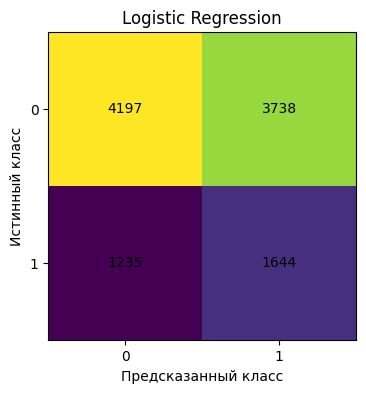

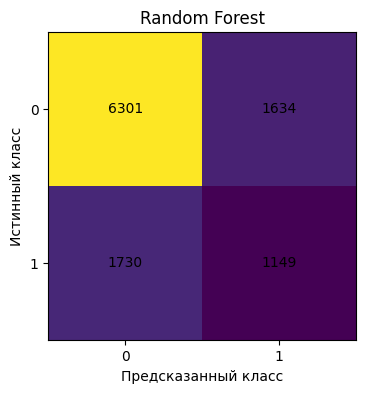

In [9]:
def show_confusion(title, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(4, 4))
    img = ax.imshow(cm)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center")
    ax.set_title(title)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    plt.show()

show_confusion("Logistic Regression", y_test, log_pred)
show_confusion("Random Forest", y_test, rf_pred)


## 11. Какие признаки использовали модели

Для логистической регрессии анализируются стандартизированные коэффициенты. Для Random Forest — feature importance. Эти показатели не являются доказательством причинности, но показывают, на какие характеристики модели опираются сильнее.


Логистическая регрессия:


,feature,coefficient,abs_importance
10,artist_popularity,0.297624,0.297624
12,release_age_days,-0.175378,0.175378
1,energy,-0.112768,0.112768
14,collab,0.100042,0.100042
9,duration,-0.091698,0.091698
7,valence,0.073067,0.073067
11,log_artist_followers,-0.067528,0.067528
3,speechiness,-0.055109,0.055109
2,loudness,0.054019,0.054019
6,liveness,-0.047299,0.047299


Random Forest:


,feature,importance
12,release_age_days,0.292389
11,log_artist_followers,0.089700
9,duration,0.061411
10,artist_popularity,0.061203
1,energy,0.059067
0,danceability,0.059007
2,loudness,0.058835
8,tempo,0.058066
4,acousticness,0.057185
6,liveness,0.055822


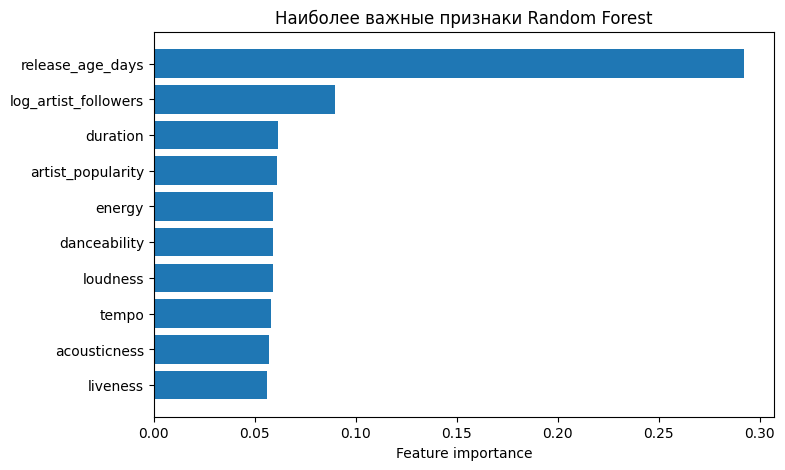

In [10]:
# Коэффициенты логистической регрессии
log_coef = logistic_model.named_steps["model"].coef_[0]

log_importance = pd.DataFrame({
    "feature": model_features,
    "coefficient": log_coef,
    "abs_importance": np.abs(log_coef)
}).sort_values("abs_importance", ascending=False)

print("Логистическая регрессия:")
display(log_importance.head(12))

# Важности Random Forest
rf_importance = pd.DataFrame({
    "feature": model_features,
    "importance": forest_model.feature_importances_
}).sort_values("importance", ascending=False)

print("Random Forest:")
display(rf_importance.head(12))

fig, ax = plt.subplots(figsize=(8, 5))
top_rf = rf_importance.head(10).sort_values("importance")
ax.barh(top_rf["feature"], top_rf["importance"])
ax.set_title("Наиболее важные признаки Random Forest")
ax.set_xlabel("Feature importance")
plt.show()


## 12. Проверка вклада текстовых признаков The Guardian

В 2.3 статьи были агрегированы до уровня исполнителя. Используются:
- средняя длина статьи;
- среднее число слов;
- суммарное число упоминаний исполнителя;
- среднее число тегов.

Покрытие Guardian в подготовленном наборе ограничено, поэтому эта проверка рассматривается как **дополнительный эксперимент**, а не как единственное основание для вывода.

Чтобы сравнение было честным, две логистические модели обучаются на одной и той же подвыборке:
1. базовые признаки без текста;
2. те же признаки + признаки Guardian.

Разделение выполняется по исполнителю, чтобы один и тот же артист не попадал и в обучение, и в тест.


In [11]:
text_features = [
    "avg_article_words",
    "total_artist_mentions",
    "avg_text_length",
    "avg_tag_count"
]
text_features = [c for c in text_features if c in df.columns]

text_comparison = None

if len(text_features) >= 3:
    text_cols = model_features + text_features + ["popular"]
    text_group_col = "artist_key" if "artist_key" in df.columns else "artist_name"

    text_df = df[text_cols + [text_group_col]].copy()

    for col in model_features + text_features:
        text_df[col] = pd.to_numeric(text_df[col], errors="coerce")

    text_df = text_df.dropna(
        subset=model_features + text_features + ["popular", text_group_col]
    )

    n_groups = text_df[text_group_col].nunique()

    print("Наблюдений с текстовыми признаками:", len(text_df))
    print("Уникальных исполнителей:", n_groups)

    if len(text_df) >= 200 and n_groups >= 5 and text_df["popular"].nunique() == 2:
        X_base = text_df[model_features]
        X_text = text_df[model_features + text_features]
        y_text = text_df["popular"]
        groups_text = text_df[text_group_col]

        splitter_text = GroupShuffleSplit(
            n_splits=1,
            test_size=0.25,
            random_state=42
        )
        tr, te = next(
            splitter_text.split(X_text, y_text, groups_text)
        )

        y_tr, y_te = y_text.iloc[tr], y_text.iloc[te]

        base_pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            ))
        ])

        text_pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            ))
        ])

        base_pipe.fit(X_base.iloc[tr], y_tr)
        text_pipe.fit(X_text.iloc[tr], y_tr)

        base_prob = base_pipe.predict_proba(X_base.iloc[te])[:, 1]
        text_prob = text_pipe.predict_proba(X_text.iloc[te])[:, 1]

        base_auc = roc_auc_score(y_te, base_prob)
        text_auc = roc_auc_score(y_te, text_prob)

        text_comparison = pd.DataFrame({
            "model": ["без текстовых признаков", "с текстовыми признаками"],
            "roc_auc": [base_auc, text_auc]
        })

        display(text_comparison.round(3))
        print("Δ ROC-AUC:", round(text_auc - base_auc, 3))
    else:
        print(
            "Подвыборка слишком мала или содержит недостаточно групп/классов "
            "для корректного группового сравнения."
        )
else:
    print(
        "Текстовые агрегаты не найдены. "
        "Запустите 2.3 и убедитесь, что загружен data/processed/music_merged.csv."
    )


Наблюдений с текстовыми признаками: 6874
Уникальных исполнителей: 8


,model,roc_auc
0,без текстовых признаков,0.735
1,с текстовыми признаками,0.697


Δ ROC-AUC: -0.038


## 13. Кластеризация композиций методом K-Means

Кластеризация используется как дополнительный исследовательский метод. В отличие от классификации, здесь заранее не задается правильный класс.

Одна композиция представляется один раз: аудиохарактеристики берутся на уровне трека, а число стримов усредняется по неделям. Затем для `k = 2...5` рассчитывается silhouette score и выбирается вариант с наибольшим значением.


In [12]:
cluster_features = [
    c for c in [
        "danceability", "energy", "loudness", "speechiness",
        "acousticness", "instrumentalness", "liveness",
        "valence", "tempo", "duration"
    ]
    if c in df.columns
]

track_group = "track_id" if "track_id" in df.columns else "track_key"

agg_map = {c: "first" for c in cluster_features}
agg_map["streams"] = "mean"

track_level = (
    df.dropna(subset=[track_group])
    .groupby(track_group, as_index=False)
    .agg(agg_map)
    .dropna(subset=cluster_features)
)

scaler_cluster = StandardScaler()
X_cluster = scaler_cluster.fit_transform(
    track_level[cluster_features]
)

silhouette_rows = []

for k in range(2, 6):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    labels = model.fit_predict(X_cluster)
    score = silhouette_score(X_cluster, labels)
    silhouette_rows.append({
        "k": k,
        "silhouette": score
    })

silhouette_df = pd.DataFrame(silhouette_rows)
display(silhouette_df.round(3))

best_k = int(
    silhouette_df.loc[
        silhouette_df["silhouette"].idxmax(),
        "k"
    ]
)

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

track_level["cluster"] = kmeans.fit_predict(X_cluster)

print("Выбрано кластеров:", best_k)


,k,silhouette
0,2,0.235
1,3,0.138
2,4,0.147
3,5,0.123


Выбрано кластеров: 2


## 14. Профили найденных кластеров

После кластеризации сравниваются средние характеристики кластеров и среднее число стримов. Если кластеры отличаются и по музыкальным характеристикам, и по уровню популярности, это дополнительно показывает наличие устойчивых сочетаний признаков.


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration,streams,tracks
cluster,,,,,,,,,,,,
0,0.599,0.445,-9.081,0.108,0.506,0.029,0.167,0.343,115.346,207419.217,7515849.962,972
1,0.716,0.693,-5.485,0.136,0.142,0.004,0.181,0.532,124.283,202766.426,7183939.078,3270


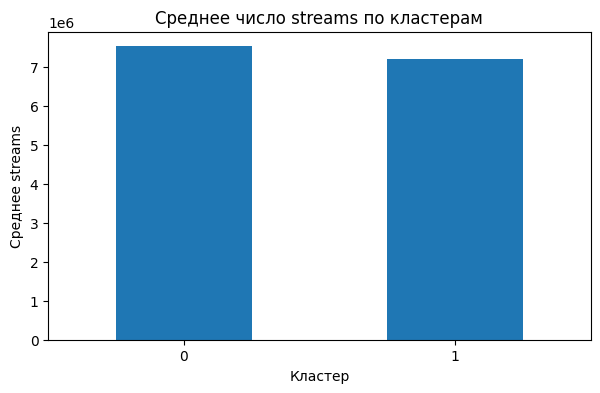

In [13]:
cluster_profile = (
    track_level.groupby("cluster")
    [cluster_features + ["streams"]]
    .mean()
)

cluster_counts = (
    track_level["cluster"]
    .value_counts()
    .sort_index()
    .rename("tracks")
)

cluster_profile = cluster_profile.join(cluster_counts)

display(cluster_profile.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
cluster_profile["streams"].plot(kind="bar", ax=ax)
ax.set_title("Среднее число streams по кластерам")
ax.set_xlabel("Кластер")
ax.set_ylabel("Среднее streams")
plt.xticks(rotation=0)
plt.show()


## 15. Автоматическая проверка критериев гипотезы

Финальная ячейка сводит результаты в несколько измеримых условий:
- число заметных корреляций;
- лучший ROC-AUC среди реальных ML-моделей;
- превосходство над baseline;
- при наличии текстовой подвыборки — изменение ROC-AUC после добавления текстовых признаков.


In [14]:
strong_corr_count = int((corr_table["abs_rho"] >= 0.10).sum())

results_check = pd.DataFrame(results)
dummy_auc = float(
    results_check.loc[
        results_check["model"] == "Dummy baseline",
        "roc_auc"
    ].iloc[0]
)

ml_rows = results_check[
    results_check["model"] != "Dummy baseline"
]

best_ml_auc = float(ml_rows["roc_auc"].max())
best_ml_name = ml_rows.loc[
    ml_rows["roc_auc"].idxmax(),
    "model"
]

core_supported = (
    strong_corr_count >= 3
    and best_ml_auc >= 0.65
    and best_ml_auc > dummy_auc
)

text_delta = None
text_supported = None

if text_comparison is not None:
    base_auc = float(
        text_comparison.loc[
            text_comparison["model"] == "без текстовых признаков",
            "roc_auc"
        ].iloc[0]
    )
    with_text_auc = float(
        text_comparison.loc[
            text_comparison["model"] == "с текстовыми признаками",
            "roc_auc"
        ].iloc[0]
    )
    text_delta = with_text_auc - base_auc
    text_supported = text_delta >= 0.02

summary = pd.DataFrame({
    "критерий": [
        "число признаков с |ρ| ≥ 0.10",
        "лучший ROC-AUC",
        "ROC-AUC Dummy baseline",
        "улучшение ROC-AUC от текста"
    ],
    "результат": [
        strong_corr_count,
        round(best_ml_auc, 3),
        round(dummy_auc, 3),
        None if text_delta is None else round(text_delta, 3)
    ]
})

display(summary)

if core_supported and text_supported is True:
    hypothesis_status = "подтверждается в рамках выбранных данных"
elif core_supported:
    hypothesis_status = (
        "частично подтверждается: основная связь обнаружена, "
        "но вклад текстовых признаков не подтвержден или пока не оценен"
    )
else:
    hypothesis_status = (
        "не получает достаточного подтверждения по заданным критериям"
    )

display(Markdown(
    f"""### Итог проверки

Лучшей моделью по ROC-AUC стала **{best_ml_name}** со значением **{best_ml_auc:.3f}**.

Количество признаков с |ρ| ≥ 0.10: **{strong_corr_count}**.

По заранее установленным критериям аналитическая гипотеза **{hypothesis_status}**.
"""
))


,критерий,результат
0,число признаков с |ρ| ≥ 0.10,3.000
1,лучший ROC-AUC,0.675
2,ROC-AUC Dummy baseline,0.500
3,улучшение ROC-AUC от текста,-0.038


### Итог проверки

Лучшей моделью по ROC-AUC стала **Random Forest** со значением **0.675**.

Количество признаков с |ρ| ≥ 0.10: **3**.

По заранее установленным критериям аналитическая гипотеза **частично подтверждается: основная связь обнаружена, но вклад текстовых признаков не подтвержден или пока не оценен**.


## 16. Вывод по этапу 2.4

На этапе 2.4 используются методы описательного анализа, корреляционный анализ, две модели бинарной классификации и кластеризация.

Логистическая регрессия нужна как интерпретируемая модель, Random Forest — как модель, способная учитывать нелинейные зависимости, а K-Means — как метод поиска естественных групп композиций без заранее заданных классов.

Главный вывод делается не по одной метрике. Учитываются одновременно корреляции, качество моделей на групповой тестовой выборке, сравнение с Dummy baseline, важность признаков и, при наличии подготовленных данных The Guardian, изменение качества после добавления текстовых характеристик.

Такой подход позволяет проверить исходную гипотезу без прямого использования позиции в чарте как предиктора и уменьшает риск утечки информации.
